Iniciando o carregamento da base de dados... (isso pode levar alguns segundos)
Dados carregados e tratados com sucesso! Gerando gráficos...


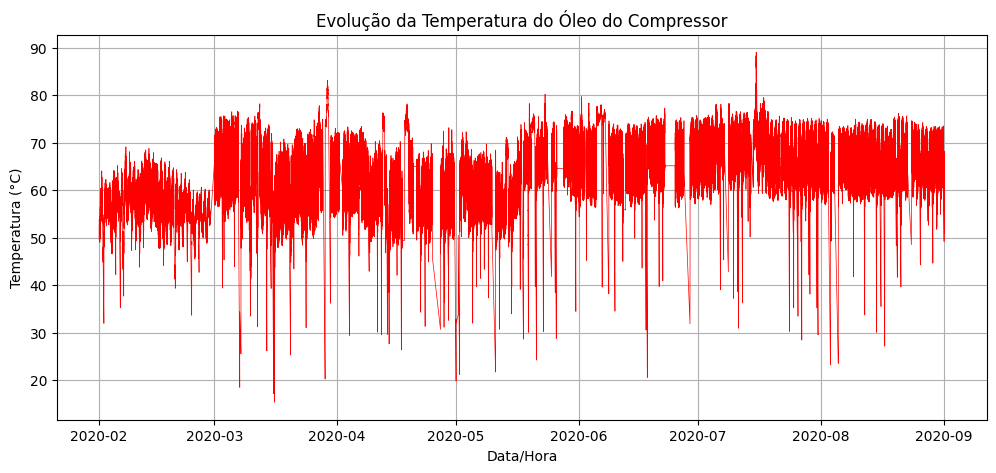

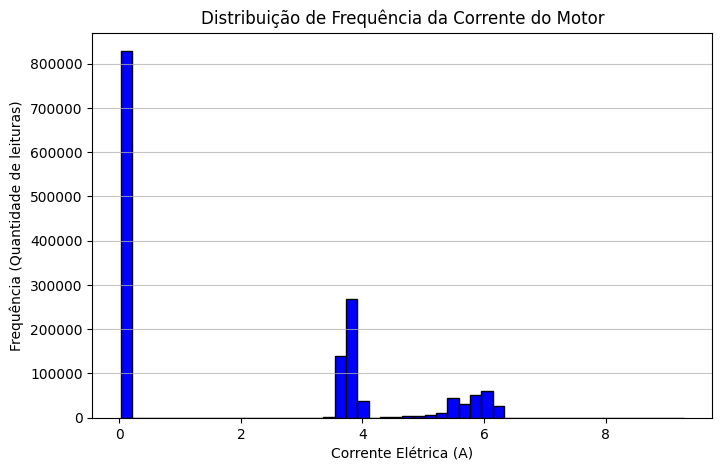

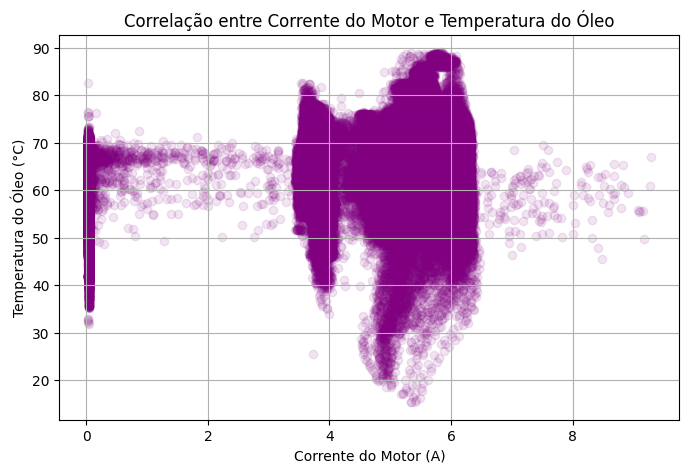

Gráficos gerados e salvos na pasta de arquivos à esquerda!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Iniciando o carregamento da base de dados... (isso pode levar alguns segundos)")

# 1. Carregar o arquivo usando o caminho exato que você encontrou
df = pd.read_csv('/MetroPT3(AirCompressor).csv')

# 2. Converter a coluna de tempo para o formato de data
df['timestamp'] = pd.to_datetime(df['timestamp'])

# 3. Tratamento de dados: garantir que as colunas principais sejam números (float)
# O Python às vezes lê os números como texto por causa do ponto flutuante.
colunas_numericas = ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current']

for col in colunas_numericas:
    # Converte para string, troca vírgula por ponto (se houver) e depois para float
    df[col] = df[col].astype(str).str.replace(',', '.').astype(float)
    # Preenche valores nulos com a média da coluna (por segurança)
    df[col] = df[col].fillna(df[col].mean())

print("Dados carregados e tratados com sucesso! Gerando gráficos...")

# ---------------------------------------------------------
# GRÁFICO 1: Série Temporal da Temperatura do Óleo
# ---------------------------------------------------------
plt.figure(figsize=(12, 5))
plt.plot(df['timestamp'], df['Oil_temperature'], color='red', linewidth=0.5)
plt.title('Evolução da Temperatura do Óleo do Compressor')
plt.xlabel('Data/Hora')
plt.ylabel('Temperatura (°C)')
plt.grid(True)
plt.savefig('grafico_temperatura.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------
# GRÁFICO 2: Histograma da Corrente do Motor
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.hist(df['Motor_current'], bins=50, color='blue', edgecolor='black')
plt.title('Distribuição de Frequência da Corrente do Motor')
plt.xlabel('Corrente Elétrica (A)')
plt.ylabel('Frequência (Quantidade de leituras)')
plt.grid(axis='y', alpha=0.75)
plt.savefig('grafico_corrente.png', dpi=300, bbox_inches='tight')
plt.show()

# ---------------------------------------------------------
# GRÁFICO 3: Dispersão (Corrente vs Temperatura)
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.scatter(df['Motor_current'], df['Oil_temperature'], alpha=0.1, color='purple')
plt.title('Correlação entre Corrente do Motor e Temperatura do Óleo')
plt.xlabel('Corrente do Motor (A)')
plt.ylabel('Temperatura do Óleo (°C)')
plt.grid(True)
plt.savefig('grafico_dispersao.png', dpi=300, bbox_inches='tight')
plt.show()

print("Gráficos gerados e salvos na pasta de arquivos à esquerda!")